# Explainable Machine Learning for Gallstone Disease

## 1. Libraries

In [1]:
import shap
import pandas as pd
import numpy as np
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, recall_score, precision_score, confusion_matrix, classification_report, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

### 1.1 Dataset

We want to flip the labels for who HAS gallstone disease and who DOES NOT have gallstone disease. For future reference: patients with Gallstone Status == 1 has Gallstone Disease and patients with Gallstone Status == 0 does not have Gallstone Disease. 

In [2]:
gd_df = pd.read_csv("dataset-uci.csv")

gd_df["Gallstone Status"] = 1 - gd_df["Gallstone Status"]
gd_df

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,1,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,1,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,1,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,1,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,1,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314,0,49,0,0,0,0,0,0,178,88.8,...,55.0,81.0,28.0,50.0,90.0,0.98,94.50,6.2,16.5,8.3
315,0,31,1,0,0,0,0,0,157,53.4,...,58.0,64.0,24.0,16.0,38.0,0.50,128.50,0.0,12.5,24.0
316,0,58,0,0,0,0,0,0,172,96.6,...,45.0,168.0,21.0,27.0,94.0,1.04,83.23,0.0,15.4,15.7
317,0,37,1,0,0,0,0,0,177,88.4,...,33.0,253.0,40.0,22.0,115.0,1.01,98.23,0.4,16.0,33.3


In [3]:
print((gd_df[gd_df["Gallstone Status"] == 1]).count())

Gallstone Status                                  161
Age                                               161
Gender                                            161
Comorbidity                                       161
Coronary Artery Disease (CAD)                     161
Hypothyroidism                                    161
Hyperlipidemia                                    161
Diabetes Mellitus (DM)                            161
Height                                            161
Weight                                            161
Body Mass Index (BMI)                             161
Total Body Water (TBW)                            161
Extracellular Water (ECW)                         161
Intracellular Water (ICW)                         161
Extracellular Fluid/Total Body Water (ECF/TBW)    161
Total Body Fat Ratio (TBFR) (%)                   161
Lean Mass (LM) (%)                                161
Body Protein Content (Protein) (%)                161
Visceral Fat Rating (VFR)   

## 2. Data Exploration

### 2.1 Initial Data Review

In [4]:
gd_df.head(10).T

,0,1,2,3,4,5,6,7,8,9
Gallstone Status,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
Age,50.00,47.00,61.00,41.00,42.00,96.00,37.00,41.00,38.00,38.00
Gender,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Comorbidity,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Coronary Artery Disease (CAD),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Hypothyroidism,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Hyperlipidemia,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Diabetes Mellitus (DM),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Height,185.00,176.00,171.00,168.00,178.00,155.00,185.00,176.00,186.00,171.00
Weight,92.80,94.50,91.10,67.70,89.60,49.00,67.10,114.00,93.70,68.60


In [5]:
gd_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 319 entries, 0 to 318
Data columns (total 39 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Gallstone Status                                319 non-null    int64  
 1   Age                                             319 non-null    int64  
 2   Gender                                          319 non-null    int64  
 3   Comorbidity                                     319 non-null    int64  
 4   Coronary Artery Disease (CAD)                   319 non-null    int64  
 5   Hypothyroidism                                  319 non-null    int64  
 6   Hyperlipidemia                                  319 non-null    int64  
 7   Diabetes Mellitus (DM)                          319 non-null    int64  
 8   Height                                          319 non-null    int64  
 9   Weight                                     

In [6]:
gd_df.shape

(319, 39)

In [7]:
gd_df.isnull().sum()

Gallstone Status                                  0
Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protein Content (Protein) (%)                0
Visceral Fat Rating (VFR)                         0
Bone Mass (B

$$\boxed{\text{No null values found}}$$

In [8]:
gd_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,319.0,0.504702,0.500763,0.00,0.000,1.000000,1.000,1.00
Age,319.0,48.068966,12.114558,20.00,38.500,49.000000,56.000,96.00
Gender,319.0,0.492163,0.500724,0.00,0.000,0.000000,1.000,1.00
Comorbidity,319.0,0.335423,0.517340,0.00,0.000,0.000000,1.000,3.00
Coronary Artery Disease (CAD),319.0,0.037618,0.190568,0.00,0.000,0.000000,0.000,1.00
Hypothyroidism,319.0,0.028213,0.165841,0.00,0.000,0.000000,0.000,1.00
Hyperlipidemia,319.0,0.025078,0.156609,0.00,0.000,0.000000,0.000,1.00
Diabetes Mellitus (DM),319.0,0.134796,0.342042,0.00,0.000,0.000000,0.000,1.00
Height,319.0,167.156740,10.053030,145.00,159.500,168.000000,175.000,191.00
Weight,319.0,80.564890,15.709069,42.90,69.600,78.800000,91.250,143.50


In [9]:
gd_df.describe().T.sort_values("std", ascending=False)

,count,mean,std,min,25%,50%,75%,max
Obesity (%),319.0,35.850125,109.799718,0.40,13.900,25.600000,41.750,1954.00
Triglyceride,319.0,144.502163,97.904493,1.39,83.000,119.000000,172.000,838.00
Total Cholesterol (TC),319.0,203.495298,45.758501,60.00,172.000,198.000000,233.000,360.00
Glucose,319.0,108.688715,44.848714,69.00,92.000,98.000000,109.000,575.00
Low Density Lipoprotein (LDL),319.0,126.652351,38.541175,11.00,100.500,122.000000,151.000,293.00
Alanin Aminotransferaz (ALT),319.0,26.855799,27.884413,3.00,14.250,19.000000,30.000,372.00
Alkaline Phosphatase (ALP),319.0,73.112539,24.181069,7.00,58.000,71.000000,86.000,197.00
High Density Lipoprotein (HDL),319.0,49.475549,17.718701,25.00,40.000,46.500000,56.000,273.00
Glomerular Filtration Rate (GFR),319.0,100.818903,16.971396,10.60,94.170,104.000000,110.745,132.00
Aspartat Aminotransferaz (AST),319.0,21.684953,16.697605,8.00,15.000,18.000000,23.000,195.00


In [10]:
gd_df.duplicated().sum()

0

### 2.2 Cleaning

We want to inspect potential outliers from some medical features:

In [11]:
#Medical ranges (these are limits we find reasonable)
medical_ranges = {
    "Age": (18, 100),
    "Weight": (30, 200),
    "High Density Lipoprotein (HDL)": (20, 100), 
    "Low Density Lipoprotein (LDL)": (50, 300), 
    "Body Mass Index (BMI)": (15, 50),
    "Creatinine": (0.5, 5.0), 
    "Glucose": (50, 400),  
    "Vitamin D": (2, 150),
    "Hemoglobin (HGB)": (8, 20),
    "Total Cholesterol (TC)": (100, 400), 
    "Triglyceride": (30, 1000),  
    "Obesity (%)": (0, 200),
    "C-Reactive Protein (CRP)": (0, 400),  
}

flagged = []
for feature, (low, high) in medical_ranges.items():
    outside = gd_df[(gd_df[feature] < low) | (gd_df[feature] > high)]
    for row, value in outside[feature].items():
        flagged.append({"row": row, "feature": feature, "value": value, "allowed": f"{low} to {high}"})
flagged = pd.DataFrame(flagged)

print(f"{len(flagged)} values outside reasonable range")
flagged

15 values outside reasonable range


,row,feature,value,allowed
0,318,High Density Lipoprotein (HDL),273.00,20 to 100
1,53,Low Density Lipoprotein (LDL),28.00,50 to 300
2,164,Low Density Lipoprotein (LDL),35.00,50 to 300
3,286,Low Density Lipoprotein (LDL),11.00,50 to 300
4,308,Low Density Lipoprotein (LDL),40.00,50 to 300
5,95,Creatinine,0.49,0.5 to 5.0
6,240,Creatinine,0.46,0.5 to 5.0
7,261,Creatinine,0.49,0.5 to 5.0
8,40,Glucose,575.00,50 to 400
9,53,Total Cholesterol (TC),60.00,100 to 400


After analyzing the dataframe above, as well as dataset statistics, we notice that the "Obesity %" of patient 239 likely is incorrect. When it comes to the other rows from the table above, none of the values are as extreme and obvious errors. Therefore we have decided to keep an extra eye on these features, but will not remove anything per now.  

In [12]:
gd_df[["Obesity (%)", "Height", "Weight"]].sort_values("Obesity (%)", ascending=False).head() # anomaly ? 

,Obesity (%),Height,Weight
239,1954.00,150,65.9
23,125.60,170,143.5
209,106.30,150,102.1
280,96.63,150,108.4
246,95.64,162,125.8


In [13]:
gd_df[["Triglyceride", "Height", "Weight"]].sort_values("Triglyceride", ascending=False).head() # anomaly ? 

,Triglyceride,Height,Weight
242,838.0,173,87.8
20,692.0,178,110.7
8,679.0,186,93.7
7,464.0,176,114.0
50,455.0,167,82.2


We notice that patient number 242 has suspicious trigliceride levels, especially when compared to the other patients in the triglycerid top 5. However, as we are not medical professionals, and this is not an obvious error, such as patient 239 with an Obesity % of 1954. We therefore concluded with keeping all of the Triglyceride rows. 

### 2.3 Visualization

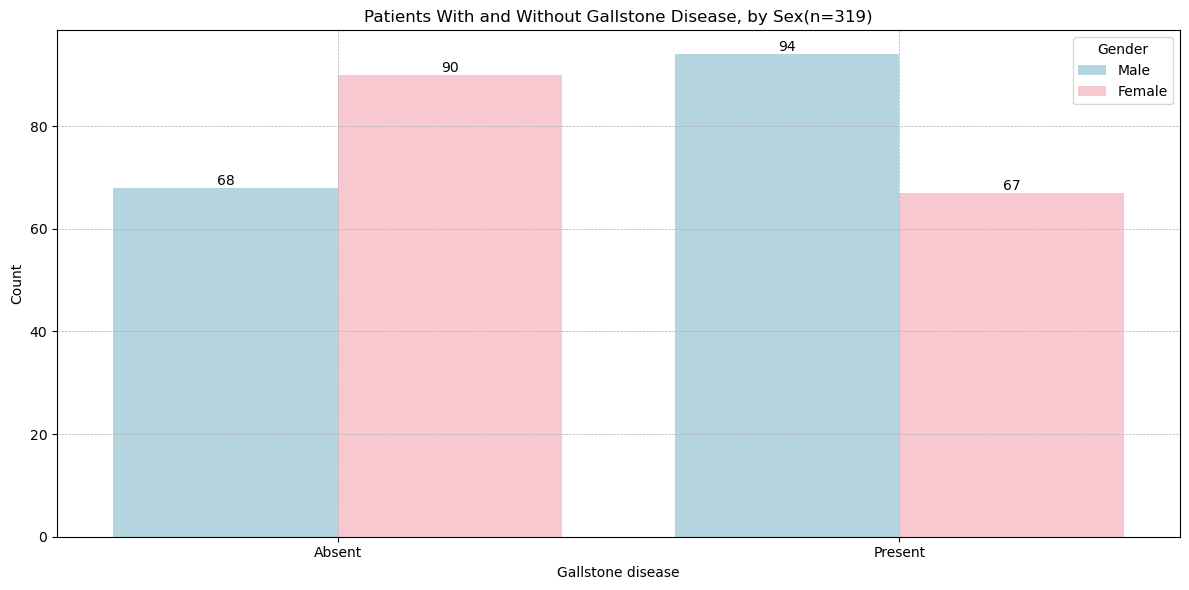

In [14]:
plt.figure(figsize=(12, 6))
plt.title("Patients With and Without Gallstone Disease, by Sex(n=319)")
ax = sns.countplot(x = "Gallstone Status", hue="Gender", data = gd_df, palette= ("lightblue", "pink"))
ax.set_xticklabels(["Absent", "Present"])

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.xlabel("Gallstone disease")
plt.ylabel("Count")
plt.tight_layout()
plt.grid(True, which="both", linestyle="--", linewidth=0.5)
plt.legend(title="Gender", loc="upper right", labels=["Male", "Female"])
plt.show()

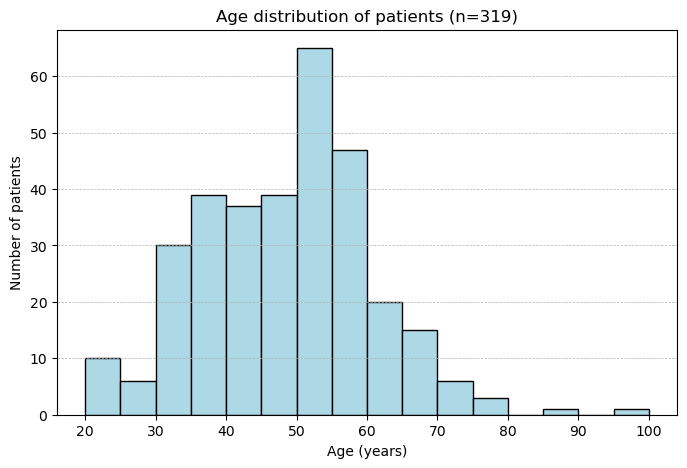

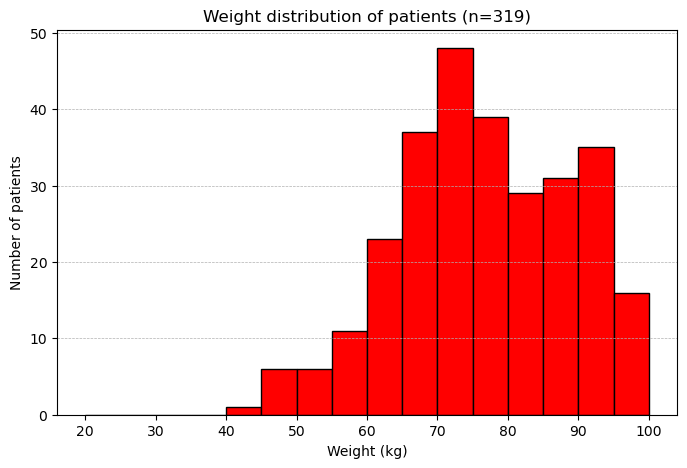

In [15]:
#Age distribution of patients
plt.figure(figsize=(8, 5))
plt.hist(gd_df["Age"], bins=range(20, 101, 5), edgecolor="black", color="lightblue")
plt.title("Age distribution of patients (n=319)")
plt.xlabel("Age (years)")
plt.ylabel("Number of patients")
plt.grid(axis="y", linestyle="--", linewidth=0.5)
plt.show()

#Weight distribution patients
plt.figure(figsize=(8, 5))
plt.hist(gd_df["Weight"], bins=range(20, 101, 5), edgecolor="black", color="red")
plt.title("Weight distribution of patients (n=319)")
plt.xlabel("Weight (kg)")
plt.ylabel("Number of patients")
plt.grid(axis="y", linestyle="--", linewidth=0.5)
plt.show()

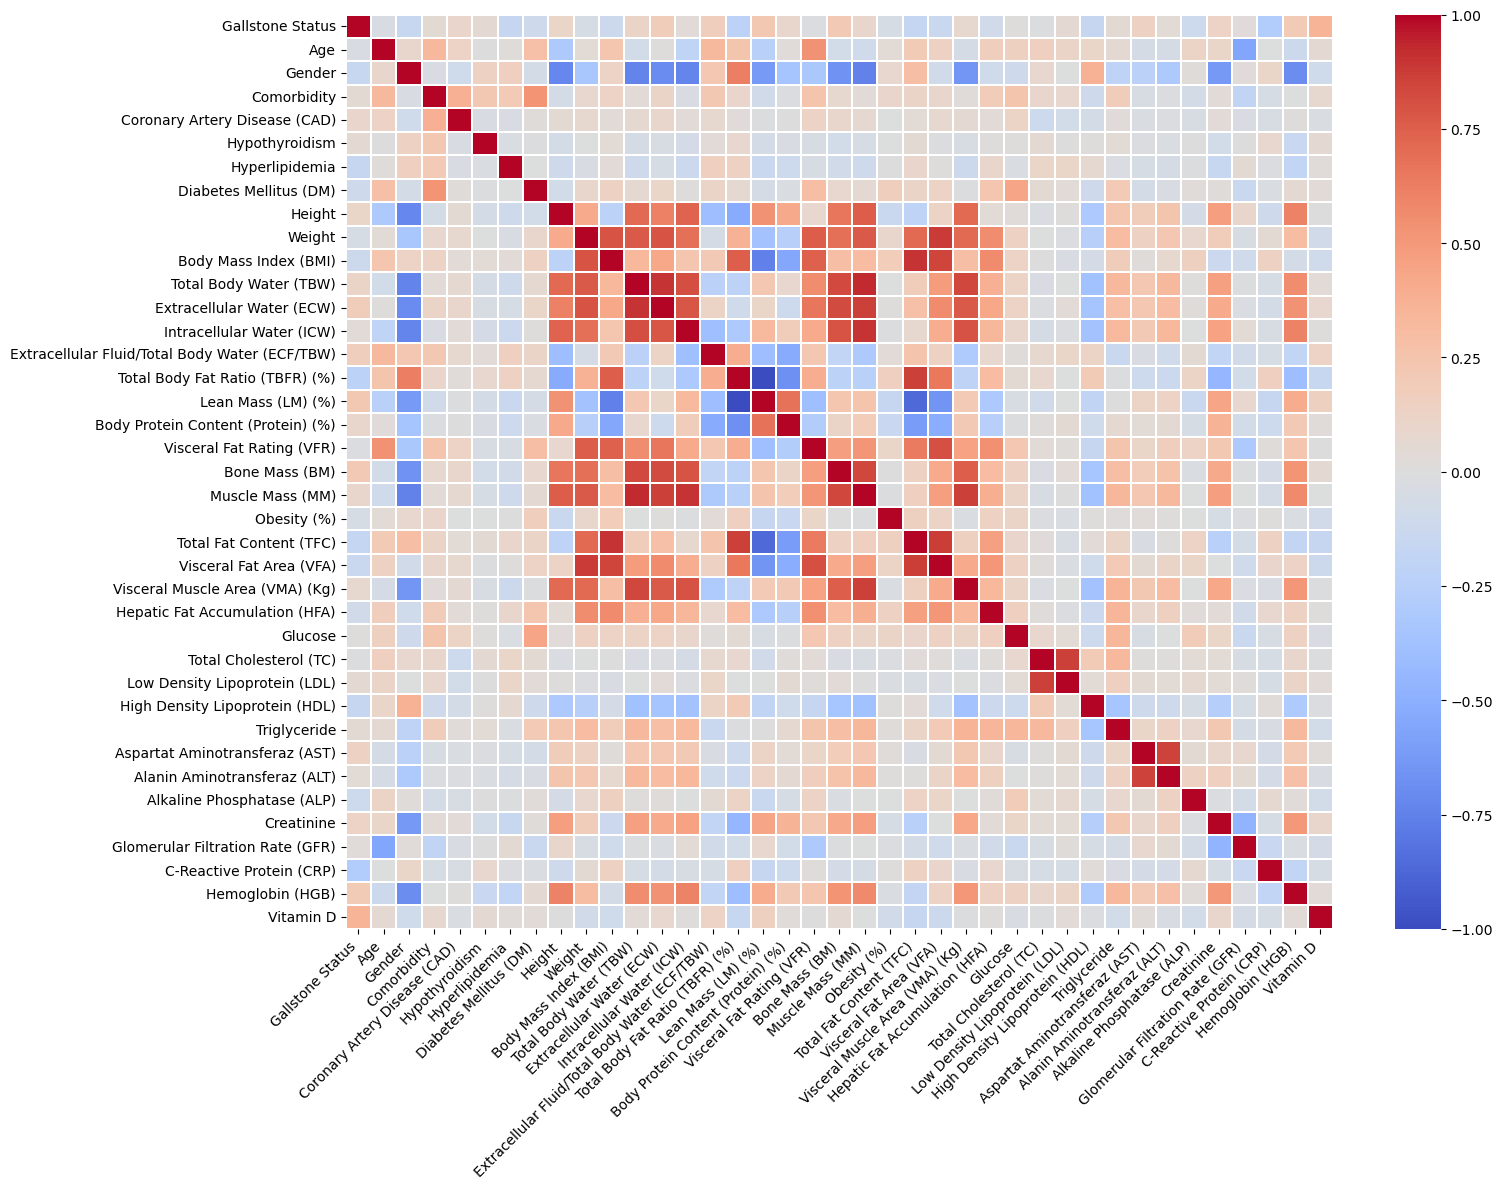

In [16]:
plt.figure(figsize=(16, 12))
sns.heatmap(gd_df.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [17]:
gd_df[["Gallstone Status", "C-Reactive Protein (CRP)"]].sort_values("C-Reactive Protein (CRP)", ascending=False).T

,214,272,231,153,270,268,257,280,277,208,...,124,125,126,127,128,129,130,131,132,318
Gallstone Status,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
C-Reactive Protein (CRP),43.4,36.7,36.1,31.0,24.5,21.4,18.8,16.5,14.0,13.9,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:
has_gallstone = gd_df[gd_df["Gallstone Status"] == 1]
has_gallstone.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,161.0,1.000000,0.000000,1.00,1.000,1.00,1.00,1.00
Age,161.0,47.633540,12.969527,20.00,38.000,49.00,56.00,96.00
Gender,161.0,0.416149,0.494457,0.00,0.000,0.00,1.00,1.00
Comorbidity,161.0,0.360248,0.565164,0.00,0.000,0.00,1.00,3.00
Coronary Artery Disease (CAD),161.0,0.055901,0.230447,0.00,0.000,0.00,0.00,1.00
Hypothyroidism,161.0,0.037267,0.190007,0.00,0.000,0.00,0.00,1.00
Hyperlipidemia,161.0,0.000000,0.000000,0.00,0.000,0.00,0.00,0.00
Diabetes Mellitus (DM),161.0,0.099379,0.300104,0.00,0.000,0.00,0.00,1.00
Height,161.0,168.229814,9.771929,145.00,162.000,170.00,175.00,188.00
Weight,161.0,79.808696,15.976226,47.30,69.200,78.00,90.50,143.50


In [19]:
no_gallstone = gd_df[gd_df["Gallstone Status"] == 0]
no_gallstone.describe().T

,count,mean,std,min,25%,50%,75%,max
Gallstone Status,158.0,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.00
Age,158.0,48.512658,11.200397,20.00,39.250000,50.000000,56.000000,76.00
Gender,158.0,0.569620,0.496704,0.00,0.000000,1.000000,1.000000,1.00
Comorbidity,158.0,0.310127,0.464016,0.00,0.000000,0.000000,1.000000,1.00
Coronary Artery Disease (CAD),158.0,0.018987,0.136914,0.00,0.000000,0.000000,0.000000,1.00
Hypothyroidism,158.0,0.018987,0.136914,0.00,0.000000,0.000000,0.000000,1.00
Hyperlipidemia,158.0,0.050633,0.219944,0.00,0.000000,0.000000,0.000000,1.00
Diabetes Mellitus (DM),158.0,0.170886,0.377606,0.00,0.000000,0.000000,0.000000,1.00
Height,158.0,166.063291,10.247065,146.00,158.000000,165.000000,174.000000,191.00
Weight,158.0,81.335443,15.444613,42.90,70.225000,79.850000,92.150000,125.80


In [20]:
gd_df.corrwith(gd_df["Gallstone Status"])

Gallstone Status                                  1.000000
Age                                              -0.036339
Gender                                           -0.153483
Comorbidity                                       0.048516
Coronary Artery Disease (CAD)                     0.096998
Hypothyroidism                                    0.055196
Hyperlipidemia                                   -0.161901
Diabetes Mellitus (DM)                           -0.104689
Height                                            0.107919
Weight                                           -0.048669
Body Mass Index (BMI)                            -0.121507
Total Body Water (TBW)                            0.111233
Extracellular Water (ECW)                         0.178436
Intracellular Water (ICW)                         0.035274
Extracellular Fluid/Total Body Water (ECF/TBW)    0.169826
Total Body Fat Ratio (TBFR) (%)                  -0.225470
Lean Mass (LM) (%)                                0.2257

### 2.4 Preprocessing

After careful consideration we decided to remove Obesity %. This is done in section 2.5 where we also remove some features based on analysis. Justification is provided in feature_selection.md.

Before we can split, we need to seperate features and labels:

In [21]:
X = gd_df.drop(["Gallstone Status"], axis = 1)
y = gd_df["Gallstone Status"]

#### Train/Test Split

In [22]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

### 2.5 Feature Selection

Look at high-correlation pairs, mutual information, drop table, ANOVA F-score, and decide which features to keep and which to drop.

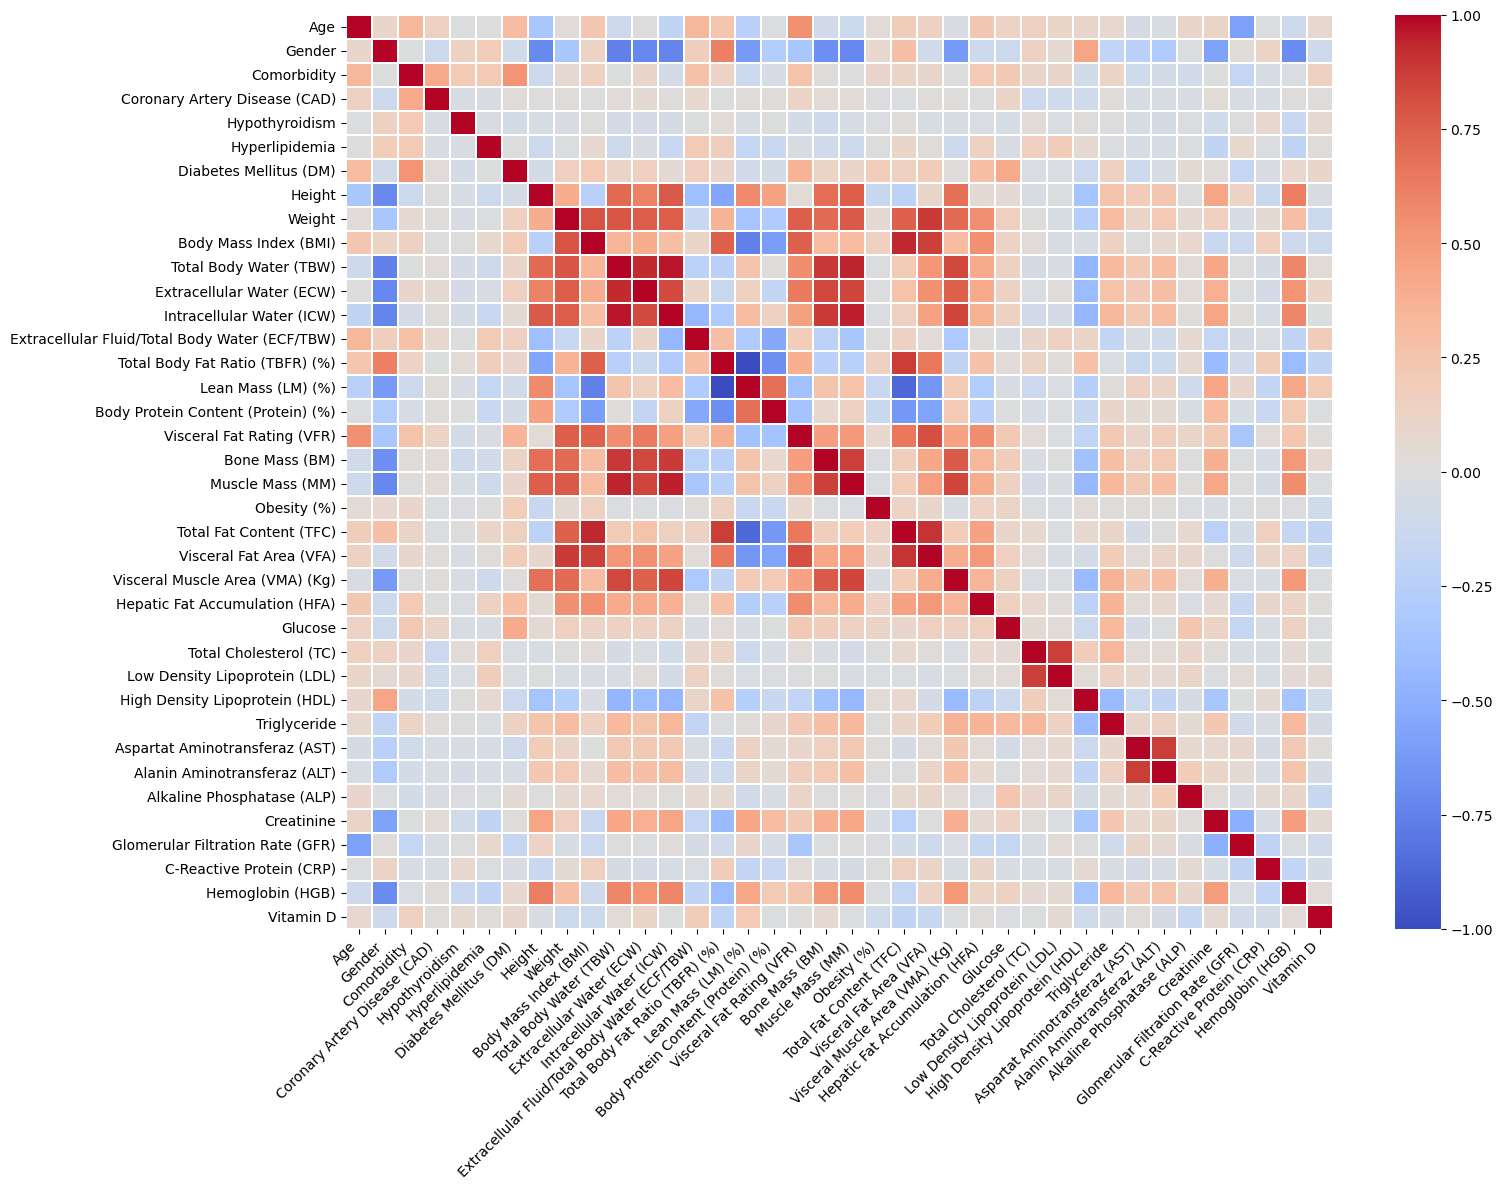

In [23]:
plt.figure(figsize=(16, 12))
sns.heatmap(X_train.corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

In [24]:
# correlation values between features
corr = X_train.corr().abs()

corr = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

high_corr = corr[(corr > 0.8) & (corr != 1)].stack()

high_corr.sort_values(ascending=False)

Total Body Fat Ratio (TBFR) (%)  Lean Mass (LM) (%)                 0.993570
Total Body Water (TBW)           Intracellular Water (ICW)          0.962050
Intracellular Water (ICW)        Muscle Mass (MM)                   0.949143
Total Body Water (TBW)           Muscle Mass (MM)                   0.937518
Body Mass Index (BMI)            Total Fat Content (TFC)            0.930670
Total Body Water (TBW)           Extracellular Water (ECW)          0.928833
Total Fat Content (TFC)          Visceral Fat Area (VFA)            0.901629
Total Body Water (TBW)           Bone Mass (BM)                     0.885555
Weight                           Visceral Fat Area (VFA)            0.881704
Intracellular Water (ICW)        Bone Mass (BM)                     0.877470
Aspartat Aminotransferaz (AST)   Alanin Aminotransferaz (ALT)       0.873189
Total Body Fat Ratio (TBFR) (%)  Total Fat Content (TFC)            0.872365
Lean Mass (LM) (%)               Total Fat Content (TFC)            0.870250

In [25]:
X_train[["Total Body Fat Ratio (TBFR) (%)", "Lean Mass (LM) (%)"]].corr()

,Total Body Fat Ratio (TBFR) (%),Lean Mass (LM) (%)
Total Body Fat Ratio (TBFR) (%),1.00000,-0.99357
Lean Mass (LM) (%),-0.99357,1.00000


In [26]:
mutual_info = mutual_info_classif(X_train, y_train, random_state=1)
mutual_info = pd.Series(mutual_info, index = X_train.columns).sort_values(ascending=False)
mutual_info

C-Reactive Protein (CRP)                          0.180214
Alkaline Phosphatase (ALP)                        0.104795
Extracellular Water (ECW)                         0.102284
Visceral Fat Area (VFA)                           0.067999
Intracellular Water (ICW)                         0.061174
Aspartat Aminotransferaz (AST)                    0.058383
Total Body Fat Ratio (TBFR) (%)                   0.057525
Extracellular Fluid/Total Body Water (ECF/TBW)    0.054503
Triglyceride                                      0.053725
Muscle Mass (MM)                                  0.053401
Total Body Water (TBW)                            0.052297
Lean Mass (LM) (%)                                0.046004
Total Cholesterol (TC)                            0.044493
Body Protein Content (Protein) (%)                0.044007
Vitamin D                                         0.040366
Visceral Fat Rating (VFR)                         0.039746
Body Mass Index (BMI)                             0.0342

In [27]:
drop_features = ["Total Body Water (TBW)", "Lean Mass (LM) (%)", "Obesity (%)"] # justification in feature_selection.md

X_train_selected = X_train.drop(columns=drop_features)
X_valid_selected = X_valid.drop(columns=drop_features)
X_test_selected = X_test.drop(columns=drop_features)

# now only 35 features
print(X_train_selected.shape)
print(X_test_selected.shape)

(223, 35)
(48, 35)


In [28]:
SEED = 132

models = {
    "Logistic Regression" : Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=SEED))
    ]),

    "Random Forest" : Pipeline([
        ("model", RandomForestClassifier(n_estimators=300, random_state=SEED))
    ]),

    "KNN" : Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM" : Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=SEED))
    ]),

    "Gradient Boost" : Pipeline([
        ("model", GradientBoostingClassifier(n_estimators=300, random_state=SEED))
    ])
}

In [29]:
results = []
roc_data = {}

for name, clf in models.items():
    clf.fit(X_train_selected, y_train)
    y_pred = clf.predict(X_valid_selected)
    y_prob = clf.predict_proba(X_valid_selected)[:,1]

    results.append({
        "model": name,
        "roc_auc": roc_auc_score(y_valid, y_prob),
        "accuracy": accuracy_score(y_valid, y_pred),
        "recall": recall_score(y_valid, y_pred),
        "precision": precision_score(y_valid, y_pred),
        "f1": f1_score(y_valid, y_pred)
    })

    fpr, tpr, _ = roc_curve(y_valid, y_prob)
    roc_data[name] = (fpr, tpr)

results_df = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
results_df

c:\Users\emilh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\emilh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\emilh\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\emilh\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\emilh\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

,model,roc_auc,accuracy,recall,precision,f1
0,Logistic Regression,0.862847,0.791667,0.875000,0.750000,0.807692
4,Gradient Boost,0.802083,0.750000,0.750000,0.750000,0.750000
1,Random Forest,0.676215,0.645833,0.625000,0.652174,0.638298
3,SVM,0.675347,0.625000,0.666667,0.615385,0.640000
2,KNN,0.574653,0.583333,0.708333,0.566667,0.629630


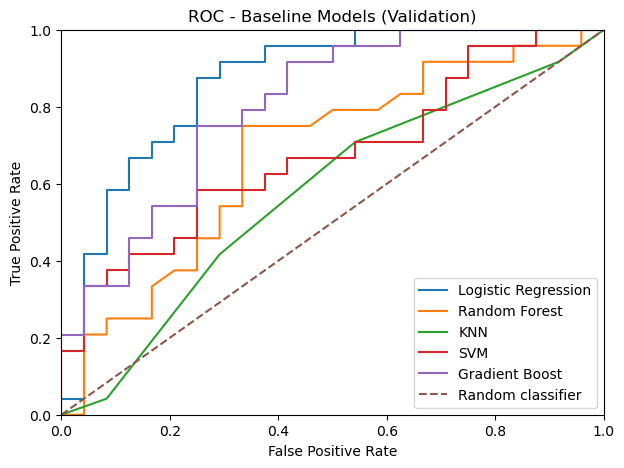

In [30]:
plt.figure(figsize=(7,5))

for name, (fpr, tpr) in roc_data.items():
    plt.plot(fpr, tpr, label = name)
    
plt.plot([0,1],[0,1], linestyle="--", label="Random classifier")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC - Baseline Models (Validation)")
plt.legend()
plt.show()

In [31]:
F_vals, p_vals = f_classif(X_train_selected, y_train)
feature_names = X_train_selected.columns

assert len(feature_names) == len(F_vals)

f_table = pd.DataFrame({
    "feature": feature_names,
    "F_score": F_vals,
    "p_value": p_vals
}).sort_values("F_score", ascending=False)

# ANOVA F-score Analysis Summary
print("="*60)
print("ANALYSIS OF VARIANCE (ANOVA) F-SCORE ANALYSIS")
print("="*60)
print(f"\nTotal features analyzed: {len(F_vals)}")
print(f"F-score range: {F_vals.min():.3f} to {F_vals.max():.3f}")
print(f"Mean F-score: {F_vals.mean():.3f}")
print(f"Median F-score: {np.median(F_vals):.3f}")
print(f"Std deviation: {F_vals.std():.3f}")
print(f"\nFeatures with F >= 1.0: {(F_vals >= 1.0).sum()}")
print(f"Features with F >= 0.70: {(F_vals >= 0.70).sum()}")

print(f"Features with p < 0.001: {(p_vals < 0.001).sum()} (extremely significant) (***)")
print(f"Features with p < 0.01: {(p_vals < 0.01).sum()} (highly significant) (**)")
print(f"Features with p < 0.05: {(p_vals < 0.05).sum()} (statistically significant) (*)")

print("\n" + "="*60)
print("TOP FEATURES BY ANOVA F-SCORE")
print("="*60)
for _, row in f_table.iterrows():
    significance = "***" if row['p_value'] < 0.001 else "**" if row['p_value'] < 0.01 else "*" if row['p_value'] < 0.05 else ""
    print(f"{row['feature']:<35} F={row['F_score']:>8.3f}  p={row['p_value']:.4e} {significance}")

print("\nSignificance: (***) p<0.001, (**) p<0.01, (*) p<0.05")

# Select features
selected_df = f_table[f_table["F_score"] >= 0.70]
selected_features = selected_df["feature"].tolist()

print(f"\nSelected {len(selected_features)} features (F >= 0.70):")
for i, row in enumerate(selected_df.itertuples(), 1):
    print(f"{i:2d}. {row.feature:<35} (F={row.F_score:.3f})")

# Transform the data
X_train_anova = X_train_selected[selected_features]    
X_valid_anova = X_valid_selected[selected_features]
X_test_anova = X_test[selected_features]

print(f"\nOriginal features: {X_train_selected.shape[1]}")
print(f"Selected features: {X_train_anova.shape[1]}")

# Compare baseline model performance with feature selection
print("\n" + "="*60)
print("Performance Comparison: All Features vs. Feature Selection")
print("="*60)

for name, clf in models.items():
    clf_all = clone(clf)
    clf_selected = clone(clf)

    clf_all.fit(X_train_selected, y_train)
    y_pred_all = clf_all.predict_proba(X_valid_selected)[: ,1]
    roc_auc_all = roc_auc_score(y_valid, y_pred_all)

    clf_selected.fit(X_train_anova, y_train)
    y_pred_selected = clf_selected.predict_proba(X_valid_anova)[: ,1]
    roc_auc_selected = roc_auc_score(y_valid, y_pred_selected)

    print(f"\n{name}:")
    print(f"  All features ({X_train_selected.shape[1]}):      ROC-AUC = {roc_auc_all:.4f}")
    print(f"  Selected features ({len(selected_features)}):  ROC-AUC = {roc_auc_selected:.4f}")
    print(f"  Difference:                {roc_auc_selected - roc_auc_all:+.4f}")

ANALYSIS OF VARIANCE (ANOVA) F-SCORE ANALYSIS

Total features analyzed: 35
F-score range: 0.012 to 35.957
Mean F-score: 6.570
Median F-score: 3.596
Std deviation: 8.329

Features with F >= 1.0: 26
Features with F >= 0.70: 26
Features with p < 0.001: 5 (extremely significant) (***)
Features with p < 0.01: 12 (highly significant) (**)
Features with p < 0.05: 17 (statistically significant) (*)

TOP FEATURES BY ANOVA F-SCORE
Vitamin D                           F=  35.957  p=8.1451e-09 ***
Total Body Fat Ratio (TBFR) (%)     F=  32.284  p=4.1755e-08 ***
Total Fat Content (TFC)             F=  18.428  p=2.6415e-05 ***
C-Reactive Protein (CRP)            F=  18.363  p=2.7249e-05 ***
Gender                              F=  13.192  p=3.4949e-04 ***
Visceral Fat Area (VFA)             F=  10.361  p=1.4809e-03 **
Hemoglobin (HGB)                    F=  10.126  p=1.6721e-03 **
Body Mass Index (BMI)               F=   9.942  p=1.8399e-03 **
Bone Mass (BM)                      F=   8.892  p=3.1853e-

## 3. Model Selection

### 3.1 Research Question

Can machine learning models effectively predict gallstone
disease, and do certain features drive the model toward the
correct decision?

### 3.2 Model Justification

#### Logistic Regession 
Logistic Regression was selected as a baseline model because it is simple and easy to interpret. It estimates the probability of gallstone disease based on the input features, providing a useful comparison for more comlex models. 

#### Random Forest
Random Forest combines multiple decision trees to make predictions. It was selected because it can capture non-linear information between features. 

#### Gradient Boost
Gradient Boosting build decision trees(scikit-learn default) sequentially, where each new tree attempts to improve the predictions of the existing model. It was selected to investigate whether the approach could improve predictive performance compared to Random Forest and the simpler models. 

#### SVM (Support Vector Machine)
SVM tries to find the best dividing line that separates the different classes, with as much space between them as possible. It was selected because it can perform well on small datasets. The Radial Basis Function(RBF) kernel, wich is used by default in sckikit-learn, allows the model find non-linear pattern between the features and gallstone disease. 

#### KNN (K-Nearest Neightbors)
KNN predicts a new observation based on its closest training observations. It was selected as a simple distance-based approach to investigate whether patients with similar characteristics also tend to have similar gallstone outcomes. 

## 4. Training

### 4.1 Data Preparation

Pipelines, cross-validation

In [32]:
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC-AUC": "roc_auc"
}

In [33]:
cross_validation = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=SEED
)

### 4.2 Cross-validation Results

In [34]:
results = {}

for name, model in models.items():
    if name in ["Logistic Regression", "Random Forest", "Gradient Boost"]:
        scores = cross_validate(
            model,
            X_train_anova,
            y_train,
            cv=cross_validation,
            scoring=scoring
        )
        results[name] = scores

### Results of 10-fold

In [35]:
comparison = pd.DataFrame()

for name, scores in results.items():
    for metric in scoring:
        mean = scores[f"test_{metric}"].mean()
        sd = scores[f"test_{metric}"].std()

        comparison.loc[name, metric] = f"{mean: .3f} ± {sd: .3f}"

display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.775 ± 0.058,0.759 ± 0.058,0.823 ± 0.112,0.785 ± 0.064,0.852 ± 0.059
Random Forest,0.781 ± 0.091,0.791 ± 0.098,0.787 ± 0.092,0.786 ± 0.078,0.851 ± 0.089
Gradient Boost,0.766 ± 0.123,0.779 ± 0.126,0.777 ± 0.118,0.772 ± 0.107,0.846 ± 0.095


## 5. Model Evaluation and Explainability

### 5.1 Metrics

We have decided to use the following metrics for evaluating machine learning model performance:

$$\text{Precision: } \quad \quad \quad \quad \frac{TP}{TP + FP}$$
$$\text{Recall: } \quad \quad \quad \quad \frac{TP}{TP + FN}$$
$$\text{F-measure: } \quad \quad \quad \quad \frac{2 \times \text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
$$\text{Accuracy: } \quad \quad \quad \quad \frac{TP + TN}{FN + TP + TN +FP}$$



TP = True Positive, FP = False Positive, TN = True Negative, FN = False Negative

### 5.2 Parameter Tuning

In [36]:
# Grid search function
def grid_search(model: str, param_grid: dict, score: str = "roc_auc"):
    '''
    Tune one model's hyperparameters with cross-validated grid search.

    Every combination in param_grid is tried with stratified 10-fold CV on the training set, scored by ROC-AUC. Prints the best parameters and their mean CV score.

    Parameters:
        model (str): Name of a model in the `models` dict, e.g. "Logistic Regression" or "KNN".
        param_grid (dict): Hyperparameters to try. Keys use the pipeline prefix, e.g. {"model__C": [0.01, 0.1, 1, 10]}.
        score (str): Metric used to rank the grid combinations, e.g. "roc_auc" or "recall". Default "roc_auc".
    '''

    grid_search = GridSearchCV(estimator=models[model],
                            param_grid=param_grid,
                            cv=cross_validation,
                            scoring=score,
                            return_train_score=True)

    grid_search.fit(X_train_anova, y_train)

    print("Best parameters: ", grid_search.best_params_)
    print("Best score: ", grid_search.best_score_)

    return grid_search

In [37]:
param_grid= {
    "model__C" : [0.01, 0.1, 1, 10, 100]
    }

lr_best = grid_search("Logistic Regression", param_grid=param_grid)

Best parameters:  {'model__C': 10}
Best score:  0.8543388429752066


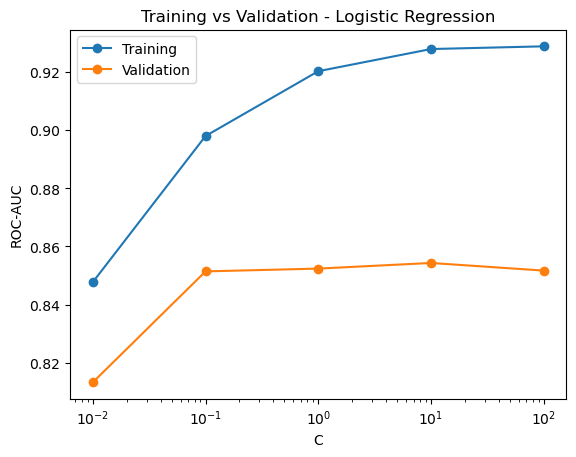

In [38]:
results = pd.DataFrame(lr_best.cv_results_)

plt.plot(
    results["param_model__C"].astype(float),
    results["mean_train_score"],
    marker="o",
    label="Training"
)

plt.plot(
    results["param_model__C"].astype(float),
    results["mean_test_score"],
    marker="o",
    label="Validation"
)

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("ROC-AUC")
plt.title("Training vs Validation - Logistic Regression")
plt.legend()
plt.show()

For Logistic Regression we decided to tune the following parameter following the results of the GridsearchCV:

- C: 1 -> 10

This value of the hyperparameter achieved the best cross validation ROC-AUC (0.85433).

The tuning gives a slight improvement in performance, whilst we still keep some regularization.

In [39]:
param_grid = {
    "model__n_estimators" : [100, 200],
    "model__max_depth" : [None, 4, 6, 8],
    "model__min_samples_leaf" : [1, 2, 4],
    "model__max_features": ["sqrt", "log2", 0.3, 0.5]
}

rf_best = GridSearchCV(estimator=models["Random Forest"],
                           param_grid=param_grid,
                           cv=cross_validation,
                           scoring="roc_auc",
                           return_train_score=True)

rf_best.fit(X_train_anova, y_train)


print("Best parameters: ", rf_best.best_params_)
print("Best score: ", rf_best.best_score_)

Best parameters:  {'model__max_depth': 6, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}
Best score:  0.8733471074380166


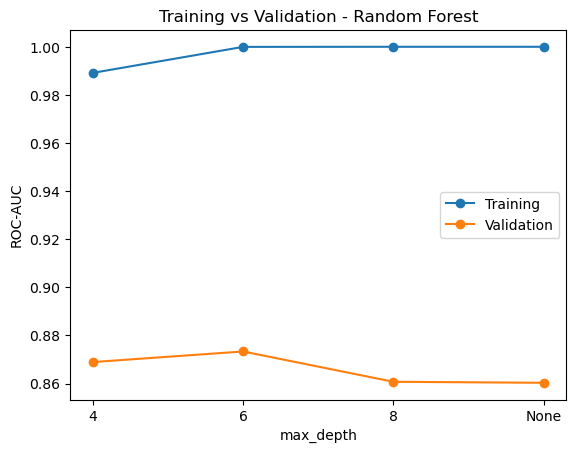

In [40]:
results = pd.DataFrame(rf_best.cv_results_)

results = results[
    (results["param_model__min_samples_leaf"] == rf_best.best_params_["model__min_samples_leaf"]) &
    (results["param_model__max_features"] == rf_best.best_params_["model__max_features"]) &
    (results["param_model__n_estimators"] == rf_best.best_params_["model__n_estimators"])
]

results = results.sort_values("param_model__max_depth", na_position="last")

plt.plot(
    results["param_model__max_depth"].astype(str),
    results["mean_train_score"],
    marker="o",
    label="Training"
)

plt.plot(
    results["param_model__max_depth"].astype(str),
    results["mean_test_score"],
    marker="o",
    label="Validation"
)

plt.xlabel("max_depth")
plt.ylabel("ROC-AUC")
plt.title("Training vs Validation - Random Forest")
plt.legend()
plt.show()

For Random Forest we decided to tune the following parameters following the results of the GridsearchCV:

- max_depth:  None -> 6
- max_features: "sqrt" -> 0.5
- min_samples_leaf: 1 -> 1 # we keep as is
- n_estimators: 100 -> 100 # we keep as is

This combination of hyperparameters achieved the best cross validation ROC-AUC (0.87335).

We chose to visualize the training and validation ROC-AUC for max_depth given the fact it is an important factor in the complexity of the tree and can help illustrate overfitting. The other hyperparameters are fixed at their best values. 

The plot shows us that the validation performance peaks at max_depth = 6, while further increasing of depth doesnt improve the performance. 

We can also observe that the ROC-AUC for training is close to 1.0. This is considerably higher than the ROC-AUC for validation, indicating the model may be overfitting the training data. However, we chose the hyperparameters based on the validation performance in stead of the training performance. The validation results still suggest reasonable generalization, and we therefore continue with these hyperparameter values.

In [41]:
param_grid = {
    "model__n_estimators" : [150, 300, 400], 
    "model__learning_rate" : [0.6, 0.5, 0.4, 0.3, 0.2, 0.1, 0.01],
    "model__max_depth" : [2, 3, 6, 8]
}

gb_best = GridSearchCV(estimator=models["Gradient Boost"],
                           param_grid=param_grid,
                           cv=cross_validation,
                           scoring="roc_auc",
                           return_train_score=True)

gb_best.fit(X_train_anova, y_train)


print("Best parameters: ", gb_best.best_params_)
print("Best score: ", gb_best.best_score_)

Best parameters:  {'model__learning_rate': 0.4, 'model__max_depth': 2, 'model__n_estimators': 300}
Best score:  0.8710055096418733


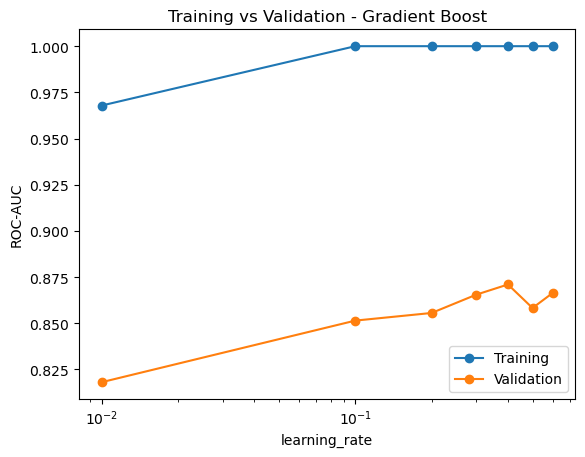

In [42]:
results = pd.DataFrame(gb_best.cv_results_)

results = results[
    (results["param_model__max_depth"] == gb_best.best_params_["model__max_depth"]) &
    (results["param_model__n_estimators"] == gb_best.best_params_["model__n_estimators"])
]

results = results.sort_values("param_model__learning_rate")

plt.plot(
    results["param_model__learning_rate"].astype(float),
    results["mean_train_score"],
    marker="o",
    label="Training"
)

plt.plot(
    results["param_model__learning_rate"].astype(float),
    results["mean_test_score"],
    marker="o",
    label="Validation"
)

plt.xscale("log")
plt.xlabel("learning_rate")
plt.ylabel("ROC-AUC")
plt.title("Training vs Validation - Gradient Boost")
plt.legend()
plt.show()

For Gradiant Boost we decided to tune the following parameters following the results of the GridsearchCV:

- n_estimators: 100 -> 300
- learning_rate: 0.1 -> 0.4
- max_depth: 3 -> 2
 
This combination of hyperparameters achieved the best cross validation ROC-AUC (0.87101).

We chose to visualize the training and validation ROC-AUC for learning_rate because it controls how much each tree contributes towards the model. It can also help illustrate overfitting. The other hyperparameters are fixed at their best values. 

The plot shows us that the validation performance peaks at learning_rate = 0.4, while further increasing of learning_rate doesnt improve the performance. 

Also in this plot we can observe that the ROC-AUC for training is close to 1.0. This is considerably higher than the ROC-AUC for validation, indicating the model may be overfitting the training data. However, we chose the hyperparameters based on the validation performance in stead of the training performance. The validation results still show signs of generalization, and we therefore continue with these hyperparameter values.

> We have now picked out 3 models we want to try out with optimal parameters which are Logistic Regression with C = 10, Random Forest with {model__max_depth': 6, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, and 'model__n_estimators': 100} and Gradient Boost with {'model__learning_rate': 0.4, 'model__max_depth': 2, 'model__n_estimators': 300}.



### 5.3 Model Evaluation

#### Logistic Regression

In [43]:
model = lr_best.best_estimator_
y_pred = model.predict(X_test_anova)
y_prob = model.predict_proba(X_test_anova)[:, 1]

In [44]:
print('Accuracy score: %.3f' % accuracy_score(y_test, y_pred))
print('F1-score: %.3f' % f1_score(y_test, y_pred))
print('Recall score: %.3f' % recall_score(y_test, y_pred))
print('Precision score: %.3f' % precision_score(y_test, y_pred))
print('ROC-AUC score: %.3f' % roc_auc_score(y_test, y_prob))

Accuracy score: 0.708
F1-score: 0.767
Recall score: 0.958
Precision score: 0.639
ROC-AUC score: 0.819


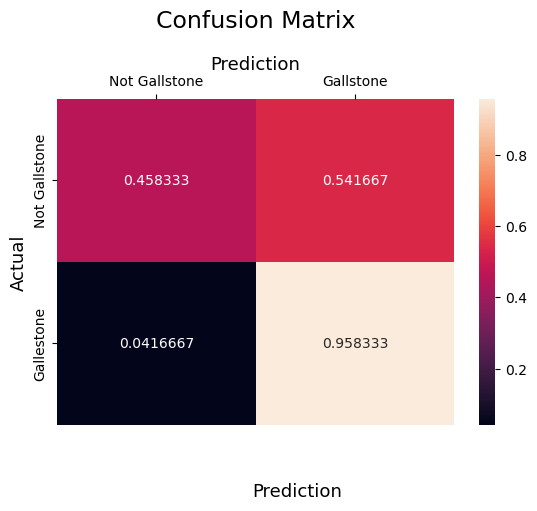

              precision    recall  f1-score   support

           0       0.92      0.46      0.61        24
           1       0.64      0.96      0.77        24

    accuracy                           0.71        48
   macro avg       0.78      0.71      0.69        48
weighted avg       0.78      0.71      0.69        48



In [45]:
cm = confusion_matrix(y_test, y_pred, normalize='true')

sns.heatmap(cm, 
            annot=True,
            fmt='g', 
            xticklabels=['Not Gallstone','Gallstone'],
            yticklabels=['Not Gallstone','Gallestone'])
plt.ylabel('Actual', fontsize=13)
plt.title('Confusion Matrix', fontsize=17, pad=20)
plt.gca().xaxis.set_label_position('top') 
plt.xlabel('Prediction', fontsize=13)
plt.gca().xaxis.tick_top()

plt.gca().figure.subplots_adjust(bottom=0.2)
plt.gca().figure.text(0.5, 0.05, 'Prediction', ha='center', fontsize=13)
plt.show()
print(classification_report(y_test, y_pred))

#### Random Forest

In [46]:
model = rf_best.best_estimator_
y_pred = model.predict(X_test_anova)
y_prob = model.predict_proba(X_test_anova)[:, 1]

In [47]:
print('Accuracy score: %.3f' % accuracy_score(y_test, y_pred))
print('F1-score: %.3f' % f1_score(y_test, y_pred))
print('Recall score: %.3f' % recall_score(y_test, y_pred))
print('Precision score: %.3f' % precision_score(y_test, y_pred))
print('ROC-AUC score: %.3f' % roc_auc_score(y_test, y_prob))

Accuracy score: 0.667
F1-score: 0.704
Recall score: 0.792
Precision score: 0.633
ROC-AUC score: 0.776


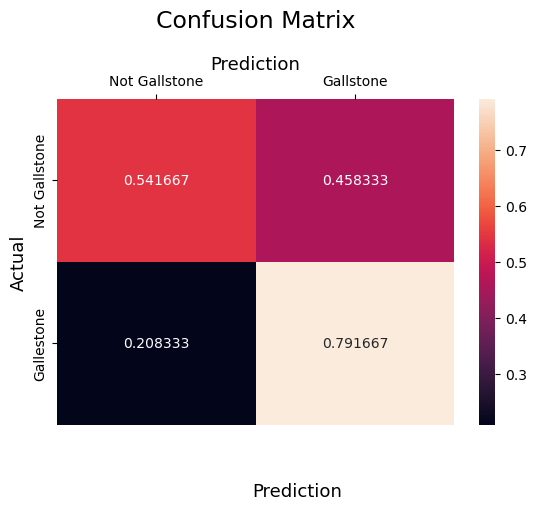

              precision    recall  f1-score   support

           0       0.72      0.54      0.62        24
           1       0.63      0.79      0.70        24

    accuracy                           0.67        48
   macro avg       0.68      0.67      0.66        48
weighted avg       0.68      0.67      0.66        48



In [48]:
cm = confusion_matrix(y_test, y_pred, normalize='true')

sns.heatmap(cm, 
            annot=True,
            fmt='g', 
            xticklabels=['Not Gallstone','Gallstone'],
            yticklabels=['Not Gallstone','Gallestone'])
plt.ylabel('Actual', fontsize=13)
plt.title('Confusion Matrix', fontsize=17, pad=20)
plt.gca().xaxis.set_label_position('top') 
plt.xlabel('Prediction', fontsize=13)
plt.gca().xaxis.tick_top()

plt.gca().figure.subplots_adjust(bottom=0.2)
plt.gca().figure.text(0.5, 0.05, 'Prediction', ha='center', fontsize=13)
plt.show()
print(classification_report(y_test, y_pred))

#### Gradient Boost

In [49]:
model = gb_best.best_estimator_
y_pred = model.predict(X_test_anova)
y_prob = model.predict_proba(X_test_anova)[:, 1]

In [50]:
print('Accuracy score: %.3f' % accuracy_score(y_test, y_pred))
print('F1-score: %.3f' % f1_score(y_test, y_pred))
print('Recall score: %.3f' % recall_score(y_test, y_pred))
print('Precision score: %.3f' % precision_score(y_test, y_pred))
print('ROC-AUC score: %.3f' % roc_auc_score(y_test, y_prob))

Accuracy score: 0.792
F1-score: 0.815
Recall score: 0.917
Precision score: 0.733
ROC-AUC score: 0.799


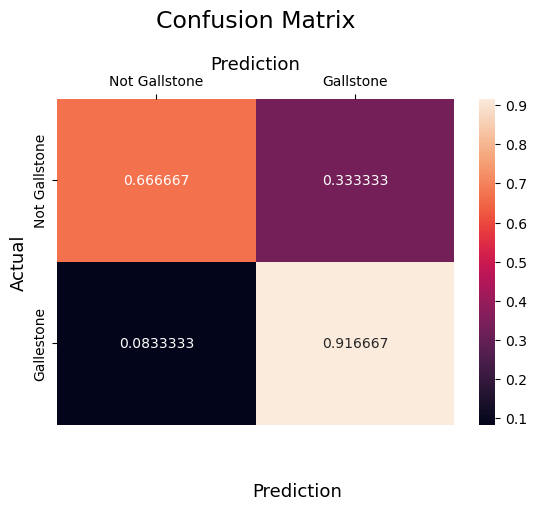

              precision    recall  f1-score   support

           0       0.89      0.67      0.76        24
           1       0.73      0.92      0.81        24

    accuracy                           0.79        48
   macro avg       0.81      0.79      0.79        48
weighted avg       0.81      0.79      0.79        48



In [51]:
cm = confusion_matrix(y_test, y_pred, normalize='true')

sns.heatmap(cm, 
            annot=True,
            fmt='g', 
            xticklabels=['Not Gallstone','Gallstone'],
            yticklabels=['Not Gallstone','Gallestone'])
plt.ylabel('Actual', fontsize=13)
plt.title('Confusion Matrix', fontsize=17, pad=20)
plt.gca().xaxis.set_label_position('top') 
plt.xlabel('Prediction', fontsize=13)
plt.gca().xaxis.tick_top()

plt.gca().figure.subplots_adjust(bottom=0.2)
plt.gca().figure.text(0.5, 0.05, 'Prediction', ha='center', fontsize=13)
plt.show()
print(classification_report(y_test, y_pred))

### 5.4 Explainability

In [52]:
# Get the trained Logistic Regression model
lr_model = lr_best.best_estimator_.named_steps["model"]

# Get the fitted scaler
scaler = lr_best.best_estimator_.named_steps["scaler"]

# Scale the data
X_train_scaled = pd.DataFrame(
    scaler.transform(X_train_anova),
    columns=X_train_anova.columns,
    index=X_train_anova.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_anova),
    columns=X_test_anova.columns,
    index=X_test_anova.index
)

In [53]:
# Create SHAP explainer
explainer = shap.LinearExplainer(lr_model, X_train_scaled)

# Calculate SHAP values
shap_values = explainer(X_test_scaled)

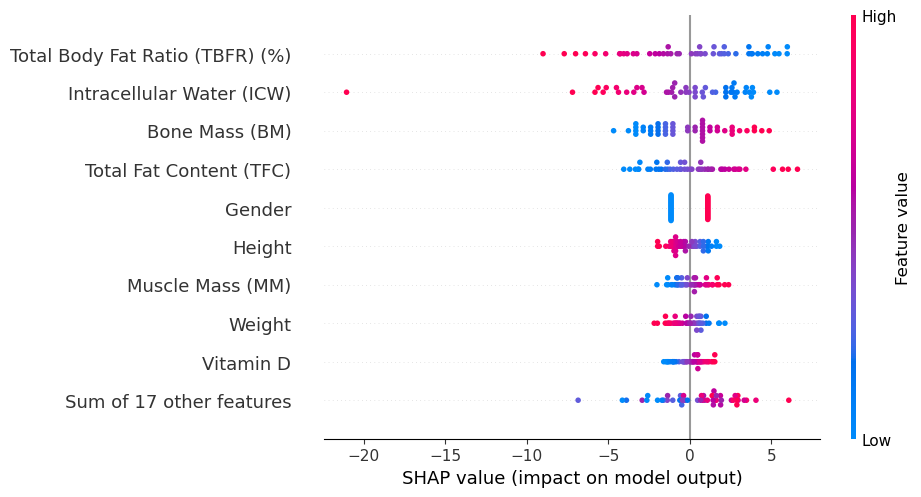

In [54]:
shap.plots.beeswarm(shap_values)

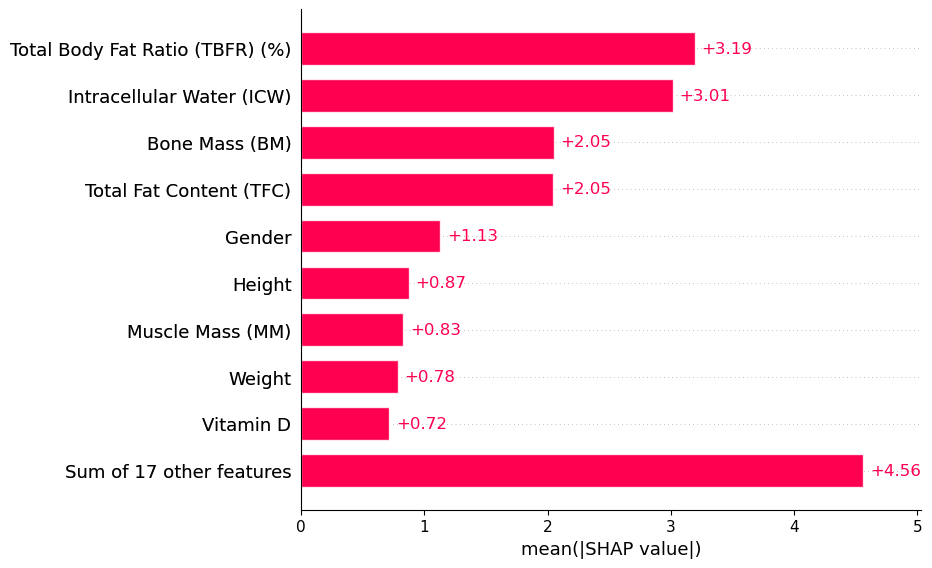

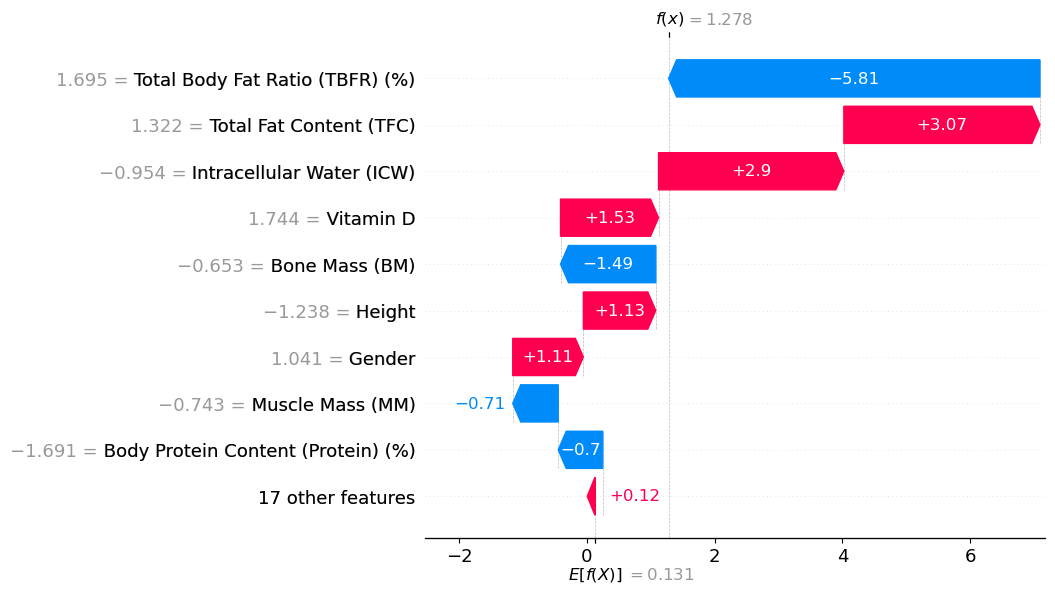

In [55]:
# Global feature importance
shap.plots.bar(shap_values)

# Explain one patient
shap.plots.waterfall(shap_values[0])